In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [51]:
df = pd.read_csv("../data/test_run3.csv")
df.head()

,id,gen,model_knowledge,w,parent_id,parent_model_knowledge,parent_w,parent_perf,perf,sim
0,g0n0,0.0,0.47,0.64,fake_parent_0,0.703310,0.765055,1.534090,-0.018184,0
1,g0n1,0.0,0.55,0.56,fake_parent_1,-0.598105,-0.828989,-0.529914,0.163926,0
2,g0n2,0.0,0.52,0.65,fake_parent_2,2.200702,-0.659151,-0.490972,0.114746,0
3,g0n3,0.0,0.45,0.70,fake_parent_3,0.688297,0.611124,-1.309165,-0.081777,0
4,g0n4,0.0,0.49,0.62,fake_parent_4,-0.006307,-0.144013,-0.008660,0.043652,0


In [55]:
df_plot = df.groupby(["gen"], as_index=False)[["perf", "model_knowledge", "w"]].mean()
df_plot

,gen,perf,model_knowledge,w
0,0.0,0.079508,0.510900,0.621600
1,1.0,0.335477,0.672480,0.672440
2,2.0,0.334109,0.670844,0.671120
3,3.0,0.340616,0.681290,0.680506
4,4.0,0.340536,0.682714,0.681102
5,5.0,0.343774,0.689394,0.688896
6,6.0,0.336970,0.673192,0.673192
7,7.0,0.337174,0.671026,0.670070
8,8.0,0.334102,0.666648,0.666648
9,9.0,0.342613,0.683596,0.682903


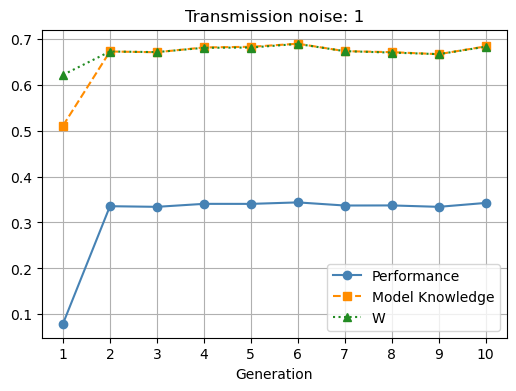

In [58]:
plt.figure(figsize=(6,4))
plt.plot(df_plot["gen"]+1, df_plot["perf"], marker="o", linestyle="-", color="steelblue", label="Performance")
plt.plot(df_plot["gen"]+1, df_plot["model_knowledge"], marker="s", linestyle="--", color="darkorange", label="Model Knowledge")
plt.plot(df_plot["gen"]+1, df_plot["w"], marker="^", linestyle=":", color="forestgreen", label="W")
plt.title("Transmission noise: 1")
plt.xlabel("Generation")
plt.xticks(np.arange(1, 11, 1))
# plt.ylim(0, 0.5)
# plt.yticks(np.arange(0, 0.51, 0.1))
plt.grid(True)
plt.legend()
plt.show()

In [115]:
model_knowledge_param = {"mean": 0.04, "sd": 0.15}
w_param = {"mean": 0.5, "sd": 0.14}
n = 10

raw_model_knowledge = np.random.normal(
    model_knowledge_param["mean"],
    model_knowledge_param["sd"],
    n
)
pop_model_knowledge = (raw_model_knowledge + 50) * 50
pop_model_knowledge = pop_model_knowledge.round(2)
raw_w = np.random.normal(w_param["mean"], w_param["sd"], n)
pop_w = 1 / (1 + np.exp(-raw_w))  # sigmoid transform
pop_w = pop_w.round(2)
print(pop_model_knowledge, pop_w)

[2513.12 2493.33 2494.98 2504.07 2500.37 2502.22 2490.04 2511.36 2500.5
 2502.08] [0.58 0.68 0.54 0.61 0.62 0.65 0.7  0.59 0.61 0.59]
